# **Identifying Key Entities in Recipe Data**


**Business Objective**:
The goal of this assignment is to train a Named Entity Recognition (NER) model using Conditional Random Fields (CRF) to extract key entities from recipe data. The model will classify words into predefined categories such as ingredients, quantities and units, enabling the creation of a structured database of recipes and ingredients that can be used to power advanced features in recipe management systems, dietary tracking apps, or e-commerce platforms.

### **Data Description**
The given data is in JSON format, representing a **structured recipe ingredient list** with **Named Entity Recognition (NER) labels**. Below is a breakdown of the data fields:

```json
[
    {
        "input": "6 Karela Bitter Gourd Pavakkai Salt 1 Onion 3 tablespoon Gram flour besan 2 teaspoons Turmeric powder Haldi Red Chilli Cumin seeds Jeera Coriander Powder Dhania Amchur Dry Mango Sunflower Oil",
        "pos": "quantity ingredient ingredient ingredient ingredient ingredient quantity ingredient quantity unit ingredient ingredient ingredient quantity unit ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient"
    },
    {
      "input": "2-1/2 cups rice cooked 3 tomatoes teaspoons BC Belle Bhat powder 1 teaspoon chickpea lentils 1/2 cumin seeds white urad dal mustard green chilli dry red 2 cashew or peanuts 1-1/2 tablespoon oil asafoetida",
      "pos": "quantity unit ingredient ingredient quantity ingredient unit ingredient ingredient ingredient ingredient quantity unit ingredient ingredient quantity ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient quantity ingredient ingredient ingredient quantity unit ingredient ingredient"
    }
]


| **Key**  | **Description**  |
|----------|-----------------|
| `input`  | Contains a raw ingredient list from a recipe. |
| `pos`    | Represents the corresponding part-of-speech (POS) tags or NER labels, identifying quantities, ingredients, and units. |


## **1** Import libraries

#### **1.1** Installation of sklearn-crfsuite

sklearn-crfsuite is a Python wrapper for CRFsuite, a fast and efficient implementation of Conditional Random Fields (CRFs). It is designed to integrate seamlessly with scikit-learn for structured prediction tasks such as Named Entity Recognition (NER), Part-of-Speech (POS) tagging, and chunking.

In [1]:
# installation of sklearn_crfsuite
!pip install sklearn_crfsuite==0.5.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 20.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [sklearn_crfsuite]


#### **1.2** Import necessary libraries

In [2]:
# Import warnings
import warnings
warnings.filterwarnings('ignore')

In [3]:
# Import necessary libraries
import json  # For handling JSON data
import pandas as pd  # For data manipulation and analysis
import re  # For regular expressions (useful for text preprocessing)
import matplotlib.pyplot as plt  # For visualisation
import seaborn as sns  # For advanced data visualisation
import sklearn_crfsuite  # CRF (Conditional Random Fields) implementation for sequence modeling
import numpy as np  # For numerical computations
# Saving and loading machine learning models
import joblib
import random
import spacy
from IPython.display import display, Markdown # For displaying well-formatted output

from fractions import Fraction  # For handling fractional values in numerical data
# Importing tools for feature engineering and model training
from collections import Counter  # For counting occurrences of elements in a list
from sklearn.model_selection import train_test_split  # For splitting dataset into train and test sets
from sklearn_crfsuite import metrics  # For evaluating CRF models
from sklearn_crfsuite.metrics import flat_classification_report
from sklearn.utils.class_weight import compute_class_weight
from collections import Counter
from sklearn.metrics import confusion_matrix

In [4]:
# Ensure pandas displays full content
pd.set_option('display.max_colwidth', None)
pd.set_option('display.expand_frame_repr', False)

## **2** Data Ingestion and Preparation <font color = red>[25 marks]</font> <br>

#### **2.1** *Read Recipe Data from Dataframe and prepare the data for analysis* <font color = red>[12 marks]</font> <br>
Read the data from JSON file, print first five rows and describe the dataframe

##### **2.1.1** **Define a *load_json_dataframe* function** <font color = red>[7 marks]</font> <br>

Define a function that takes path of the ingredient_and_quantity.json file and reads it, convert it into dataframe - df and return it.

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
# define a function to load json file to a dataframe
import json
import pandas as pd

def load_json_to_dataframe(file_path='/content/drive/MyDrive/Starter+Notebook+++Data (2) (2)/ingredient_and_quantity.json'):
    """
    Load a JSON file and convert it into a Pandas DataFrame.
    """
    with open(file_path, 'r', encoding='utf-8') as file:
        data = json.load(file)

    df = pd.DataFrame(data)
    return df

##### **2.1.2** **Execute the *load_json_dataframe* function** <font color = red>[2 marks]</font> <br>

In [7]:
# read the json file by giving the file path and create a dataframe
import json
import pandas as pd
file_path = '/content/drive/MyDrive/Starter+Notebook+++Data (2) (2)/ingredient_and_quantity.json'
with open(file_path, 'r', encoding='utf-8') as file:
    data = json.load(file)
df = pd.DataFrame(data)

##### **2.1.3** **Describe the dataframe** <font color = red>[3 marks]</font> <br>

Print first five rows of dataframe along with dimensions. Display the information of dataframe

In [8]:
# display first five rows of the dataframe - df
display(df.head())

,input,pos
0,6 Karela Bitter Gourd Pavakkai Salt 1 Onion 3 tablespoon Gram flour besan 2 teaspoons Turmeric powder Haldi Red Chilli Cumin seeds Jeera Coriander Powder Dhania Amchur Dry Mango Sunflower Oil,quantity ingredient ingredient ingredient ingredient ingredient quantity ingredient quantity unit ingredient ingredient ingredient quantity unit ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient
1,2-1/2 cups rice cooked 3 tomatoes teaspoons BC Belle Bhat powder 1 teaspoon chickpea lentils 1/2 cumin seeds white urad dal mustard green chilli dry red 2 cashew or peanuts 1-1/2 tablespoon oil asafoetida,quantity unit ingredient ingredient quantity ingredient unit ingredient ingredient ingredient ingredient quantity unit ingredient ingredient quantity ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient quantity ingredient ingredient ingredient quantity unit ingredient ingredient
2,1-1/2 cups Rice Vermicelli Noodles Thin 1 Onion sliced 1/2 cup Carrots Gajjar chopped 1/3 Green peas Matar 2 Chillies 1/4 teaspoon Asafoetida hing Mustard seeds White Urad Dal Split Ghee sprig Curry leaves Salt Lemon juice,quantity unit ingredient ingredient ingredient ingredient quantity ingredient ingredient quantity unit ingredient ingredient ingredient quantity ingredient ingredient ingredient quantity ingredient quantity unit ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient unit ingredient ingredient ingredient ingredient ingredient
3,500 grams Chicken 2 Onion chopped 1 Tomato 4 Green Chillies slit inch Ginger finely 6 cloves Garlic 1/2 teaspoon Turmeric powder Haldi Garam masala tablespoon Sesame Gingelly Oil 1/4 Methi Seeds Fenugreek Coriander Dhania Dry Red Fennel seeds Saunf cups Sorrel Leaves Gongura picked and,quantity unit ingredient quantity ingredient ingredient quantity ingredient quantity ingredient ingredient ingredient unit ingredient ingredient quantity unit ingredient quantity unit ingredient ingredient ingredient ingredient ingredient unit ingredient ingredient ingredient quantity ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient unit ingredient ingredient ingredient ingredient ingredient
4,1 tablespoon chana dal white urad 2 red chillies coriander seeds 3 inches ginger onion tomato Teaspoon mustard asafoetida sprig curry,quantity unit ingredient ingredient ingredient ingredient quantity ingredient ingredient ingredient ingredient quantity unit ingredient ingredient ingredient unit ingredient ingredient unit ingredient


In [9]:
# print the dimensions of dataframe - df
print(df.shape)

(285, 2)


In [10]:
# print the information of the dataframe
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 285 entries, 0 to 284
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   input   285 non-null    object
 1   pos     285 non-null    object
dtypes: object(2)
memory usage: 4.6+ KB
None


#### **2.2** *Recipe Data Manipulation* <font color = red>[13 marks]</font> <br>
Create derived metrics in dataframe and provide insights of the dataframe

##### **2.2.1** **Create input_tokens and pos_tokens columns by splitting the input and pos from the dataframe** <font color = red>[3 marks]</font> <br>
Split the input and pos into input_tokens and pos_tokens in the dataframe and display it in the dataframe

In [11]:
# split the input and pos into input_tokens and pos_tokens in the dataframe

# Tokenize input
df['input_tokens'] = df['input'].apply(lambda x: x.split())
# Tokenize POS
df['pos_tokens'] = df['pos'].apply(lambda x: x.split())

In [12]:
# display first five rows of the dataframe - df
df.head()

,input,pos,input_tokens,pos_tokens
0,6 Karela Bitter Gourd Pavakkai Salt 1 Onion 3 tablespoon Gram flour besan 2 teaspoons Turmeric powder Haldi Red Chilli Cumin seeds Jeera Coriander Powder Dhania Amchur Dry Mango Sunflower Oil,quantity ingredient ingredient ingredient ingredient ingredient quantity ingredient quantity unit ingredient ingredient ingredient quantity unit ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient,"[6, Karela, Bitter, Gourd, Pavakkai, Salt, 1, Onion, 3, tablespoon, Gram, flour, besan, 2, teaspoons, Turmeric, powder, Haldi, Red, Chilli, Cumin, seeds, Jeera, Coriander, Powder, Dhania, Amchur, Dry, Mango, Sunflower, Oil]","[quantity, ingredient, ingredient, ingredient, ingredient, ingredient, quantity, ingredient, quantity, unit, ingredient, ingredient, ingredient, quantity, unit, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient]"
1,2-1/2 cups rice cooked 3 tomatoes teaspoons BC Belle Bhat powder 1 teaspoon chickpea lentils 1/2 cumin seeds white urad dal mustard green chilli dry red 2 cashew or peanuts 1-1/2 tablespoon oil asafoetida,quantity unit ingredient ingredient quantity ingredient unit ingredient ingredient ingredient ingredient quantity unit ingredient ingredient quantity ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient quantity ingredient ingredient ingredient quantity unit ingredient ingredient,"[2-1/2, cups, rice, cooked, 3, tomatoes, teaspoons, BC, Belle, Bhat, powder, 1, teaspoon, chickpea, lentils, 1/2, cumin, seeds, white, urad, dal, mustard, green, chilli, dry, red, 2, cashew, or, peanuts, 1-1/2, tablespoon, oil, asafoetida]","[quantity, unit, ingredient, ingredient, quantity, ingredient, unit, ingredient, ingredient, ingredient, ingredient, quantity, unit, ingredient, ingredient, quantity, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, quantity, ingredient, ingredient, ingredient, quantity, unit, ingredient, ingredient]"
2,1-1/2 cups Rice Vermicelli Noodles Thin 1 Onion sliced 1/2 cup Carrots Gajjar chopped 1/3 Green peas Matar 2 Chillies 1/4 teaspoon Asafoetida hing Mustard seeds White Urad Dal Split Ghee sprig Curry leaves Salt Lemon juice,quantity unit ingredient ingredient ingredient ingredient quantity ingredient ingredient quantity unit ingredient ingredient ingredient quantity ingredient ingredient ingredient quantity ingredient quantity unit ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient unit ingredient ingredient ingredient ingredient ingredient,"[1-1/2, cups, Rice, Vermicelli, Noodles, Thin, 1, Onion, sliced, 1/2, cup, Carrots, Gajjar, chopped, 1/3, Green, peas, Matar, 2, Chillies, 1/4, teaspoon, Asafoetida, hing, Mustard, seeds, White, Urad, Dal, Split, Ghee, sprig, Curry, leaves, Salt, Lemon, juice]","[quantity, unit, ingredient, ingredient, ingredient, ingredient, quantity, ingredient, ingredient, quantity, unit, ingredient, ingredient, ingredient, quantity, ingredient, ingredient, ingredient, quantity, ingredient, quantity, unit, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, unit, ingredient, ingredient, ingredient, ingredient, ingredient]"
3,500 grams Chicken 2 Onion chopped 1 Tomato 4 Green Chillies slit inch Ginger finely 6 cloves Garlic 1/2 teaspoon Turmeric powder Haldi Garam masala tablespoon Sesame Gingelly Oil 1/4 Methi Seeds Fenugreek Coriander Dhania Dry Red Fennel seeds Saunf cups Sorrel Leaves Gongura picked and,quantity unit ingredient quantity ingredient ingredient quantity ingredient quantity ingredient ingredient ingredient unit ingredient ingredient qua

##### **2.2.2** **Provide the length for input_tokens and pos_tokens and validate their length** <font color = red>[2 marks]</font> <br>

Create input_length and pos_length columns in the dataframe and validate both the lengths. Check for the rows that are unequal in input and pos length


In [13]:
# create input_length and pos_length columns for the input_tokens and pos-tokens
df['input_length'] = df['input_tokens'].apply(len)
df['pos_length'] = df['pos_tokens'].apply(len)

In [14]:
# check for the equality of input_length and pos_length in the dataframe
df['input_length'].equals(df['pos_length'])

False

##### **2.2.3** **Define a unique_labels function and validate the labels in pos_tokens** <font color = red>[2 marks]</font> <br>

Define a unique_labels function which checks for all the unique pos labels in the recipe & execute it.


In [15]:
# Define a unique_labels function to checks for all the unique pos labels in the recipe & print it
def unique_labels(pos_tokens):
    labels = set()
    for tokens in pos_tokens:
        labels.update(tokens)
    return sorted(labels)

# Execute the function
labels = unique_labels(df['pos_tokens'])

print("Unique POS labels:", labels)
print("Total unique labels:", len(labels))

Unique POS labels: ['ingredient', 'quantity', 'unit']
Total unique labels: 3


##### **2.2.3** **Provide the insights seen in the recipe data after validation** <font color = red>[1 marks]</font> <br>

Provide the indexes that requires cleaning and formatting in the dataframe

In [16]:
# Identify indexes that require cleaning and formatting
mismatch_indexes = df.index[df['input_length'] != df['pos_length']].tolist()

print("Indexes requiring cleaning and formatting:")
print(mismatch_indexes)

print("Total number of rows requiring cleaning:", len(mismatch_indexes))

Indexes requiring cleaning and formatting:
[17, 27, 79, 164, 207]
Total number of rows requiring cleaning: 5


In [17]:
df.loc[mismatch_indexes, [
    'input', 'pos',
    'input_tokens', 'pos_tokens',
    'input_length', 'pos_length'
]]

,input,pos,input_tokens,pos_tokens,input_length,pos_length
17,2 cups curd 1 cup gourd cucumber green cor coriander 1/2 teaspoon cumin powder salt,quantity unit ingredient quantity unit ingredient ingredient ingredient ingredient quantity unit ingredient ingredient ingredient,"[2, cups, curd, 1, cup, gourd, cucumber, green, cor, coriander, 1/2, teaspoon, cumin, powder, salt]","[quantity, unit, ingredient, quantity, unit, ingredient, ingredient, ingredient, ingredient, quantity, unit, ingredient, ingredient, ingredient]",15,14
27,1 Baguette sliced 1 1/2 tablespoon Butter 1/2 Garlic minced cup Spinach Leaves Palak Red Bell pepper Capsicum Tomato finely chopped Onion Black powder Italian seasoning teaspoon Fresh cream Cheddar cheese grated Salt Roasted tomato pasta sauce,quantity ingredient ingredient quantity unit ingredient quantity ingredient ingredient unit ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient unit ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient,"[1, Baguette, sliced, 1, 1/2, tablespoon, Butter, 1/2, Garlic, minced, cup, Spinach, Leaves, Palak, Red, Bell, pepper, Capsicum, Tomato, finely, chopped, Onion, Black, powder, Italian, seasoning, teaspoon, Fresh, cream, Cheddar, cheese, grated, Salt, Roasted, tomato, pasta, sauce]","[quantity, ingredient, ingredient, quantity, unit, ingredient, quantity, ingredient, ingredient, unit, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, unit, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient]",37,36
79,1/2 cup Poha Flattened rice 2 tablespoons Rice flour 2 1/2 liter Milk 1 Nolen Gur or brown sugar Cardamom Elaichi Pods/Seeds 8-10 Mixed nuts almonds/cashews tablespoon Raisins pinch Saffron strands and a little more for garnish Salt,quantity unit ingredient ingredient ingredient quantity unit ingredient ingredient quantity unit ingredient quantity ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient quantity ingredient ingredient ingredient unit ingredient unit ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient,"[1/2, cup, Poha, Flattened, rice, 2, tablespoons, Rice, flour, 2, 1/2, liter, Milk, 1, Nolen, Gur, or, brown, sugar, Cardamom, Elaichi, Pods/Seeds, 8-10, Mixed, nuts, almonds/cashews, tablespoon, Raisins, pinch, Saffron, strands, and, a, little, more, for, garnish, Salt]","[quantity, unit, ingredient, ingredient, ingredient, quantity, unit, ingredient, ingredient, quantity, unit, ingredient, quantity, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, quantity, ingredient, ingredient, ingredient, unit, ingredient, unit, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient]",38,37
164,1/2 cup All Purpose Flour Maida Whole Wheat 1/4 Hung Curd Greek Yogurt 250 grams Chicken minced 1 Spinach Leaves Palak finely chopped Onion 4 cloves Garlic Tomatoes tablespoon Cumin powder Jeera Coriander Powder Dhania 1 1/2 teaspoon Paprika Black pepper 3 sprig Mint Pudina 10 Spring Bulb & Greens 100 Feta Cheese crumbled,quantity unit ingredient ingredient ingredient ingredient ingredient ingredient quantity ingredient ingredient ingredient ingredient quantity unit ingredient ingredient quantity ingredient ingredient ingredient ingredient ingredient ingredient quantity unit ingredient ingredient unit ingredient ingredient ingredient ingredient ingredient ingredient quantity unit ingredient ingredient ingredient quantity unit ingredient ingredient quantity ingredient ingredient ingredient ingredient quantity ingredient ingredient ingredient,"[

<font color = red>[**Insights from Data Validation**]</font> <br>

The validation of the recipe dataset revealed that five records, with indexes **17, 27, 79, 164, and 207**, have mismatches between the number of input tokens and their corresponding POS labels.

In all five records, the number of POS labels is one less than the number of input tokens. These inconsistencies may result from missing labels, annotation errors, or tokenization issues involving quantities and compound ingredient names.

These records require further inspection and appropriate cleaning before model training. Ensuring that each input token has a corresponding POS label is essential for maintaining data integrity and improving the reliability of the Conditional Random Field (CRF) Named Entity Recognition model.


##### **2.2.4** **Drop the rows that have invalid data provided in previous cell** <font color = red> [2 marks]</font> <br>

In [18]:
# drop the irrelevant recipe data
df.drop(index=[17, 27, 79, 164, 207], inplace=True)


In [19]:
# Reset the index after dropping rows
df.reset_index(drop=True, inplace=True)

In [20]:
# Check for remaining mismatches
print("Remaining mismatched rows:",
      (df['input_length'] != df['pos_length']).sum())

# Display the updated dimensions
print("Updated dataframe dimensions:", df.shape)

Remaining mismatched rows: 0
Updated dataframe dimensions: (280, 6)


##### **2.2.5** **Update the input_length & pos_length in dataframe**<font color = red> [2 marks]</font> <br>

In [21]:
# update the input and pos length in input_length and pos_length
df['input_length'] = df['input_tokens'].apply(len)
df['pos_length'] = df['pos_tokens'].apply(len)

In [22]:
# Verify updated length
print(df[['input_length', 'pos_length']].head())

print("Remaining mismatches:",
      (df['input_length'] != df['pos_length']).sum())

   input_length  pos_length
0            31          31
1            34          34
2            37          37
3            46          46
4            21          21
Remaining mismatches: 0


##### **2.2.6** **Validate the input_length and pos_length by checking unequal rows** <font color = red> [1 marks]</font> <br>

In [23]:
# validate the input length and pos length as input_length and pos_length
df[df['input_length'] != df['pos_length']]

,input,pos,input_tokens,pos_tokens,input_length,pos_length


In [24]:
# check number of invalid rows
print("Number of unequal rows:",
      (df['input_length'] != df['pos_length']).sum())

Number of unequal rows: 0


## **3** Train Validation Split (70 train - 30 val) <font color = red>[6 marks]</font> <br>

#### **3.1** *Perform train and validation split ratio* <font color = red>[6 marks]</font> <br>
Split the dataset with the help of input_tokens and pos_tokens and make a ratio of 70:30 split for training and validation datasets.

###### **3.1.1** **Split the dataset into train_df and val_df into 70:30 ratio** <font color = red> [1 marks]</font> <br>

In [25]:
# split the dataset into training and validation sets
from sklearn.model_selection import train_test_split
train_df, val_df = train_test_split(
    df,
    test_size = 0.30,
    random_state = 42
)

In [26]:
print("Training dataset shape:", train_df.shape)
print("Validation dataset shape:", val_df.shape)

print("Training percentage:", round(len(train_df) / len(df) * 100, 2), "%")
print("Validation percentage:", round(len(val_df) / len(df) * 100, 2), "%")

Training dataset shape: (196, 6)
Validation dataset shape: (84, 6)
Training percentage: 70.0 %
Validation percentage: 30.0 %


###### **3.1.2** **Print the first five rows of train_df and val_df** <font color = red> [1 marks]</font> <br>

In [27]:
# print the first five rows of train_df
display(train_df.head())

,input,pos,input_tokens,pos_tokens,input_length,pos_length
175,250 grams Okra Oil 1 Onion finely chopped Tomato Grated teaspoon Ginger 2 Garlic Finely 1/2 Cumin seeds 1/4 Teaspoon asafoetida cup cottage cheese pinched coriander powder mango red chilli turmeric,quantity unit ingredient ingredient quantity ingredient ingredient ingredient ingredient ingredient unit ingredient quantity ingredient ingredient quantity ingredient ingredient quantity unit ingredient unit ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient,"[250, grams, Okra, Oil, 1, Onion, finely, chopped, Tomato, Grated, teaspoon, Ginger, 2, Garlic, Finely, 1/2, Cumin, seeds, 1/4, Teaspoon, asafoetida, cup, cottage, cheese, pinched, coriander, powder, mango, red, chilli, turmeric]","[quantity, unit, ingredient, ingredient, quantity, ingredient, ingredient, ingredient, ingredient, ingredient, unit, ingredient, quantity, ingredient, ingredient, quantity, ingredient, ingredient, quantity, unit, ingredient, unit, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient]",31,31
55,200 grams Paneer Homemade Cottage Cheese 2 Potato Aloo Bay leaf tej patta Dry Red Chilli 1 tablespoon Panch Phoran Masala roasted and powdered Tomato big sized teaspoon Turmeric powder Haldi Cumin seeds Jeera Ginger grated Salt 1/2 Sugar Sunflower Oil,quantity unit ingredient ingredient ingredient ingredient quantity ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient quantity unit ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient unit ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient quantity ingredient ingredient ingredient,"[200, grams, Paneer, Homemade, Cottage, Cheese, 2, Potato, Aloo, Bay, leaf, tej, patta, Dry, Red, Chilli, 1, tablespoon, Panch, Phoran, Masala, roasted, and, powdered, Tomato, big, sized, teaspoon, Turmeric, powder, Haldi, Cumin, seeds, Jeera, Ginger, grated, Salt, 1/2, Sugar, Sunflower, Oil]","[quantity, unit, ingredient, ingredient, ingredient, ingredient, quantity, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, quantity, unit, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, unit, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, quantity, ingredient, ingredient, ingredient]",41,41
109,500 grams Cabbage Patta Gobi Muttaikose 1 teaspoon Mustard seeds 1-1/2 White Urad Dal Split sprig Curry leaves Green Chilli 1/4 cup Fresh coconut Salt,quantity unit ingredient ingredient ingredient ingredient quantity unit ingredient ingredient quantity ingredient ingredient ingredient ingredient unit ingredient ingredient ingredient ingredient quantity unit ingredient ingredient ingredient,"[500, grams, Cabbage, Patta, Gobi, Muttaikose, 1, teaspoon, Mustard, seeds, 1-1/2, White, Urad, Dal, Split, sprig, Curry, leaves, Green, Chilli, 1/4, cup, Fresh, coconut, Salt]","[quantity, unit, ingredient, ingredient, ingredient, ingredient, quantity, unit, ingredient, ingredient, quantity, ingredient, ingredient, ingredient, ingredient, unit, ingredient, ingredient, ingredient, ingredient, quantity, unit, ingredient, ingredient, ingredient]",25,25
213,500 grams Fresh Figs 1/4 cup Lemon juice 1 teaspoon zest 2 Red Chilli flakes 1/2 Honey Brown Sugar (Demerara Sugar),quantity unit ingredient ingredient quantity unit ingredient ingredient quantity unit ingredient quantity ingredient ingredient ingredient quantity ingredient ingredient ingredient ingredient ingredient,"[500, grams, Fresh, Figs, 1/4, cup, Lemon, juice, 1, teaspoon, zest, 2, Red, Chilli, flakes, 1/2, Honey, Brown, Sugar, (Demerara, Sugar)]","[quantity, unit, ingredient, ingredient, quantity, unit, ingredient, ingredient, qua

In [28]:
# print the first five rows of the val_df
display(val_df.head(5))

,input,pos,input_tokens,pos_tokens,input_length,pos_length
33,1 cup Ada 2 liter Milk 3/4 Sugar tablespoon Ghee 1/2 teaspoon Cardamom Powder Elaichi,quantity unit ingredient quantity unit ingredient quantity ingredient unit ingredient quantity unit ingredient ingredient ingredient,"[1, cup, Ada, 2, liter, Milk, 3/4, Sugar, tablespoon, Ghee, 1/2, teaspoon, Cardamom, Powder, Elaichi]","[quantity, unit, ingredient, quantity, unit, ingredient, quantity, ingredient, unit, ingredient, quantity, unit, ingredient, ingredient, ingredient]",15,15
108,1 Carrot Gajjar chopped 7 Potatoes Aloo 2 cups Cauliflower gobi cut to small florets Onion tablespoon Ginger Garlic Paste Salt teaspoons Sunflower Oil 1/2 cup Fresh coconut grated teaspoon Whole Black Peppercorns Green Chillies Fennel seeds Saunf Poppy 6 Cashew nuts inch Cinnamon Stick Dalchini Star anise 3 Cloves Laung Cardamom Elaichi Pods/Seeds Cumin Jeera,quantity ingredient ingredient ingredient quantity ingredient ingredient quantity unit ingredient ingredient ingredient ingredient ingredient ingredient ingredient unit ingredient ingredient ingredient ingredient unit ingredient ingredient quantity unit ingredient ingredient ingredient unit ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient ingredient quantity ingredient ingredient unit ingredient ingredient ingredient ingredient ingredient quantity ingredient ingredient ingredient ingredient ingredient ingredient ingredient,"[1, Carrot, Gajjar, chopped, 7, Potatoes, Aloo, 2, cups, Cauliflower, gobi, cut, to, small, florets, Onion, tablespoon, Ginger, Garlic, Paste, Salt, teaspoons, Sunflower, Oil, 1/2, cup, Fresh, coconut, grated, teaspoon, Whole, Black, Peppercorns, Green, Chillies, Fennel, seeds, Saunf, Poppy, 6, Cashew, nuts, inch, Cinnamon, Stick, Dalchini, Star, anise, 3, Cloves, Laung, Cardamom, Elaichi, Pods/Seeds, Cumin, Jeera]","[quantity, ingredient, ingredient, ingredient, quantity, ingredient, ingredient, quantity, unit, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, unit, ingredient, ingredient, ingredient, ingredient, unit, ingredient, ingredient, quantity, unit, ingredient, ingredient, ingredient, unit, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, quantity, ingredient, ingredient, unit, ingredient, ingredient, ingredient, ingredient, ingredient, quantity, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient]",56,56
240,1 tablespoon Sunflower Oil 3 Potato Aloo Ginger paste Green Chilli chopped 1-1/12 tablespoons Sesame seeds Til teaspoon Red powder Cumin Jeera Coriander Powder Dhania 1/2 Garam masala 2 Sweet Chutney Date Tamarind Leaves few,quantity unit ingredient ingredient quantity ingredient ingredient ingredient ingredient ingredient ingredient ingredient quantity unit ingredient ingredient ingredient unit ingredient ingredient ingredient ingredient ingredient ingredient ingredient quantity ingredient ingredient quantity ingredient ingredient ingredient ingredient ingredient ingredient,"[1, tablespoon, Sunflower, Oil, 3, Potato, Aloo, Ginger, paste, Green, Chilli, chopped, 1-1/12, tablespoons, Sesame, seeds, Til, teaspoon, Red, powder, Cumin, Jeera, Coriander, Powder, Dhania, 1/2, Garam, masala, 2, Sweet, Chutney, Date, Tamarind, Leaves, few]","[quantity, unit, ingredient, ingredient, quantity, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, quantity, unit, ingredient, ingredient, ingredient, unit, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient, quantity, ingredient, ingredient, quantity, ingredient, ingredient, ingredient, ingredient, ingredient, ingredient]",35,35
259,1 cup green peas gram flour 1/2 cheese tsp ginger 2 chillies turmeric powder cumin teaspoon salt oil,quantity unit ingredient ingredient ingredient ingredient quantity ingredient unit ingredient quantity ingredient i

###### **3.1.3** **Extract the dataset into train_df and val_df into X_train, X_val, y_train and y_val and display their length** <font color = red> [2 marks]</font> <br>

Extract X_train, X_val, y_train and y_val by extracting the list of input_tokens and pos_tokens from train_df and val_df and also display their length

In [29]:
# extract the training and validation sets by taking input_tokens and pos_tokens
x_train = train_df['input_tokens'].tolist()
x_val = val_df['input_tokens'].tolist()
y_train = train_df['pos_tokens'].tolist()
y_val = val_df['pos_tokens'].tolist()

# Display their lengths
print("Length of x_train:", len(x_train))
print("Length of x_val:", len(x_val))
print("Length of y_train:", len(y_train))
print("Length of y_val:", len(y_val))

Length of x_train: 196
Length of x_val: 84
Length of y_train: 196
Length of y_val: 84


In [30]:
# validate the shape of training and validation samples
print("x_train shape:", len(x_train))
print("y_train shape:", len(y_train))

print("x_val shape:", len(x_val))
print("y_val shape:", len(y_val))

x_train shape: 196
y_train shape: 196
x_val shape: 84
y_val shape: 84


###### **3.1.4** **Display the number of unique labels present in y_train** <font color = red> [2 marks]</font> <br>

In [31]:
# Display the number of unique labels present in y_train
unique_train_labels = set(
   label
   for recipe_labels in y_train
   for label in recipe_labels
)
print("Number of unique labels in y_train:", len(unique_train_labels))
print("Unique labels:", sorted(unique_train_labels))

Number of unique labels in y_train: 3
Unique labels: ['ingredient', 'quantity', 'unit']


## **4** Exploratory Recipe Data Analysis on Training Dataset <font color = red>[16 marks]</font> <br>

#### **4.1** *Flatten the lists for input_tokens & pos_tokens* <font color = red>[2 marks]</font> <br>

Define a function **flatten_list** for flattening the structure for input_tokens and pos_tokens. The input parameter passed to this function is a nested list.

Initialise the dataset_name with a value ***'Training'***




In [32]:
# flatten the list for nested_list (input_tokens, pos_tokens)
def flatten_list(nested_list):
    return [item for sublist in nested_list for item in sublist]

In [33]:
# initialise the dataset_name
dataset_name = 'Training'

#### **4.2** *Extract and validate the tokens after using the flattening technique* <font color = red>[2 marks]</font> <br>

Define a function named ***extract_and_validate_tokens*** with parameters dataframe and dataset_name (Training/Validation), validate the length of input_tokens and pos_tokens from dataframe and display first 10 records for both the input_tokens and pos_tokens. Execute this function




In [34]:
# define a extract_and_validate_tokens with parameters (df, dataset_name)
def extract_and_validate_tokens(df, dataset_name):
    # call the flatten_list and apply it on input_tokens and pos_tokens
    input_tokens = flatten_list(df['input_tokens'].tolist())
    pos_tokens = flatten_list(df['pos_tokens'].tolist())

    # validate their length and display first 10 records having input and pos tokens
    print(f"Dataset: {dataset_name}")
    print("Total input tokens:", len(input_tokens))
    print("Total POS tokens:", len(pos_tokens))

    if len(input_tokens) == len(pos_tokens):
        print("Validation successful: Input and POS token lengths are equal.")
    else:
        print("Validation failed: Input and POS token lengths are unequal.")
    # Display the first 10 records
    print("\nFirst 10 input tokens:")
    print(input_tokens[:10])

    print("\nFirst 10 POS tokens:")
    print(pos_tokens[:10])

    return input_tokens, pos_tokens


In [35]:
# Call the function to display and validate the first 10 records for the training dataset
extract_and_validate_tokens(train_df, dataset_name)

Dataset: Training
Total input tokens: 7114
Total POS tokens: 7114
Validation successful: Input and POS token lengths are equal.

First 10 input tokens:
['250', 'grams', 'Okra', 'Oil', '1', 'Onion', 'finely', 'chopped', 'Tomato', 'Grated']

First 10 POS tokens:
['quantity', 'unit', 'ingredient', 'ingredient', 'quantity', 'ingredient', 'ingredient', 'ingredient', 'ingredient', 'ingredient']


(['250',
  'grams',
  'Okra',
  'Oil',
  '1',
  'Onion',
  'finely',
  'chopped',
  'Tomato',
  'Grated',
  'teaspoon',
  'Ginger',
  '2',
  'Garlic',
  'Finely',
  '1/2',
  'Cumin',
  'seeds',
  '1/4',
  'Teaspoon',
  'asafoetida',
  'cup',
  'cottage',
  'cheese',
  'pinched',
  'coriander',
  'powder',
  'mango',
  'red',
  'chilli',
  'turmeric',
  '200',
  'grams',
  'Paneer',
  'Homemade',
  'Cottage',
  'Cheese',
  '2',
  'Potato',
  'Aloo',
  'Bay',
  'leaf',
  'tej',
  'patta',
  'Dry',
  'Red',
  'Chilli',
  '1',
  'tablespoon',
  'Panch',
  'Phoran',
  'Masala',
  'roasted',
  'and',
  'powdered',
  'Tomato',
  'big',
  'sized',
  'teaspoon',
  'Turmeric',
  'powder',
  'Haldi',
  'Cumin',
  'seeds',
  'Jeera',
  'Ginger',
  'grated',
  'Salt',
  '1/2',
  'Sugar',
  'Sunflower',
  'Oil',
  '500',
  'grams',
  'Cabbage',
  'Patta',
  'Gobi',
  'Muttaikose',
  '1',
  'teaspoon',
  'Mustard',
  'seeds',
  '1-1/2',
  'White',
  'Urad',
  'Dal',
  'Split',
  'sprig',
  'Curry',
 

In [36]:
# validate the first 10 records for the validation dataset
flat_val_input_tokens, flat_val_pos_tokens = extract_and_validate_tokens(
    val_df, 'Validation'
)

Dataset: Validation
Total input tokens: 2876
Total POS tokens: 2876
Validation successful: Input and POS token lengths are equal.

First 10 input tokens:
['1', 'cup', 'Ada', '2', 'liter', 'Milk', '3/4', 'Sugar', 'tablespoon', 'Ghee']

First 10 POS tokens:
['quantity', 'unit', 'ingredient', 'quantity', 'unit', 'ingredient', 'quantity', 'ingredient', 'unit', 'ingredient']


In [37]:
# extract the tokens and its pos tags
tokens = flatten_list(train_df['input_tokens'].tolist())
pos_tags = flatten_list(train_df['pos_tokens'].tolist())

# Display the first 10 tokens and POS tags
for token, tag in zip(tokens[:10], pos_tags[:10]):
    print(token, "->", tag)

250 -> quantity
grams -> unit
Okra -> ingredient
Oil -> ingredient
1 -> quantity
Onion -> ingredient
finely -> ingredient
chopped -> ingredient
Tomato -> ingredient
Grated -> ingredient


#### **4.3** *Categorise tokens into labels (unit, ingredient, quantity)* <font color = red>[2 marks]</font> <br>

Define a function ***categorize_tokens*** to categorise tokens into ingredients, units and quantities by using extracted tokens in the previous code and return a list of ingredients, units and quantities. Execute this function to get the list.



In [38]:
# define a categorize_tokens function and provide the tokens and pos_tags as parameters and create ingredient, unit and quantity list and return it
def categorize_tokens(tokens, pos_tags):

    # Validate the labels
    if len(tokens) != len(pos_tags):
        return [], [], []

    valid_labels = {'ingredient', 'unit', 'quantity'}

    if not set(pos_tags).issubset(valid_labels):
        return [], [], []

    # Create lists for each category
    ingredient = []
    unit = []
    quantity = []

    # Categorize tokens based on POS tags
    for token, tag in zip(tokens, pos_tags):
        if tag == 'ingredient':
            ingredient.append(token)
        elif tag == 'unit':
            unit.append(token)
        elif tag == 'quantity':
            quantity.append(token)

    return ingredient, unit, quantity

# Categorize the training tokens
ingredient, unit, quantity = categorize_tokens(tokens, pos_tags)

# Display the results
print("Ingredients:", ingredient[:10])
print("Units:", unit[:10])
print("Quantities:", quantity[:10])

print("\nTotal ingredients:", len(ingredient))
print("Total units:", len(unit))
print("Total quantities:", len(quantity))

# validate the list that it comprised of these labels, if not return empty arrays
# Validate labels; return empty lists if invalid
def categorize_tokens(tokens, pos_tags):

    valid_labels = {'ingredient', 'unit', 'quantity'}

    # Check token-label length equality and label validity
    if len(tokens) != len(pos_tags) or not set(pos_tags).issubset(valid_labels):
        return [], [], []

    ingredient = []
    unit = []
    quantity = []

    for token, tag in zip(tokens, pos_tags):
        if tag == 'ingredient':
            ingredient.append(token)
        elif tag == 'unit':
            unit.append(token)
        elif tag == 'quantity':
            quantity.append(token)

    return ingredient, unit, quantity


Ingredients: ['Okra', 'Oil', 'Onion', 'finely', 'chopped', 'Tomato', 'Grated', 'Ginger', 'Garlic', 'Finely']
Units: ['grams', 'teaspoon', 'Teaspoon', 'cup', 'grams', 'tablespoon', 'teaspoon', 'grams', 'teaspoon', 'sprig']
Quantities: ['250', '1', '2', '1/2', '1/4', '200', '2', '1', '1/2', '500']

Total ingredients: 5323
Total units: 811
Total quantities: 980


In [39]:
#  call the function to categorise the labels into respective list

ingredient, unit, quantity = categorize_tokens(tokens, pos_tags)

# Display the first 10 elements of each list
print("Ingredients:", ingredient[:10])
print("Units:", unit[:10])
print("Quantities:", quantity[:10])

# Display the total number of tokens in each category
print("\nTotal ingredients:", len(ingredient))
print("Total units:", len(unit))
print("Total quantities:", len(quantity))

Ingredients: ['Okra', 'Oil', 'Onion', 'finely', 'chopped', 'Tomato', 'Grated', 'Ginger', 'Garlic', 'Finely']
Units: ['grams', 'teaspoon', 'Teaspoon', 'cup', 'grams', 'tablespoon', 'teaspoon', 'grams', 'teaspoon', 'sprig']
Quantities: ['250', '1', '2', '1/2', '1/4', '200', '2', '1', '1/2', '500']

Total ingredients: 5323
Total units: 811
Total quantities: 980


#### **4.4** *Top 10 Most Frequent Items* <font color = red>[3 marks]</font> <br>

Define a function ***get_top_frequent_items*** to display top 10 most frequent items

Here, item_list is used as a general parameter where you will call this function for ingredient and unit list

Execute this function separately for top 10 most units and ingredients



In [40]:
# define a function get_top_frequent_items to get the top frequent items by using item_list, pos label and dataset_name(Training/Validation) and return top items
from collections import Counter

# Define a function to get the top frequent items
def get_top_frequent_items(item_list, pos_label, dataset_name):

    # Count the frequency of each item
    item_counts = Counter(item_list)

    # Get the top 10 most frequent items
    top_items = item_counts.most_common(10)

    # Display the results
    print(f"Top 10 most frequent {pos_label}s in {dataset_name} dataset:")
    for item, count in top_items:
        print(f"{item}: {count}")

    return top_items

In [41]:
# get the top ingredients which are frequently seen in the recipe
top_10_ingredients = get_top_frequent_items(ingredient, 'ingredients', 'Training')

Top 10 most frequent ingredientss in Training dataset:
powder: 129
Salt: 102
seeds: 89
Green: 85
chopped: 84
Oil: 83
Red: 81
Chilli: 77
Coriander: 71
Sunflower: 65


In [42]:
# get the top units which are frequently seen in the recipe
top_10_units = get_top_frequent_items(
    unit, 'unit', 'Training'
)

Top 10 most frequent units in Training dataset:
teaspoon: 162
cup: 136
tablespoon: 99
grams: 63
tablespoons: 61
inch: 52
cups: 50
sprig: 41
cloves: 39
teaspoons: 39


#### **4.5** *Plot Top 10 most frequent items* <font color = red>[2 marks]</font> <br>




Define a function ***plot_top_items*** to plot a bar graph on top 10 most frequent items for units and ingredients

Here, item_list is used as a general parameter where you will call this function for ingredient and unit list

In [43]:
# define plot top items with parameters - top_item list, label to suggest whether its ingredient or unit, dataset_name
import matplotlib.pyplot as plt

# Define plot_top_items
def plot_top_items(top_item_list, label, dataset_name):

    # Extract item names and frequencies
    items = [item[0] for item in top_item_list]
    frequencies = [item[1] for item in top_item_list]

    # Plot bar graph
    plt.figure(figsize=(10, 5))
    plt.bar(items, frequencies)

    plt.title(f'Top 10 Most Frequent {label.title()}s - {dataset_name} Dataset')
    plt.xlabel(label.title())
    plt.ylabel('Frequency')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

#### **4.6** *Perform EDA analysis* <font color = red>[5 marks]</font> <br>

Plot the bar plots for ingredients and units and provide the insights for training dataset

---



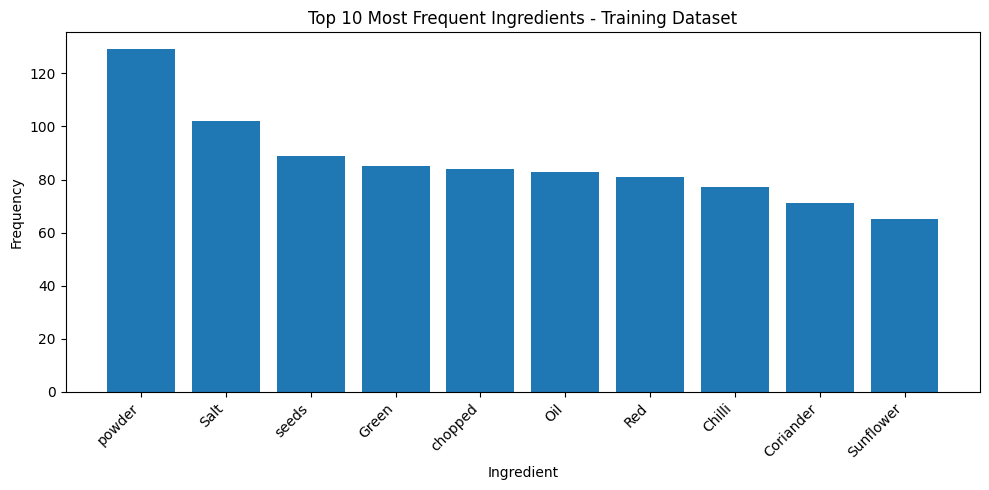

In [44]:
# plot the top frequent ingredients in training data
plot_top_items(top_10_ingredients, 'ingredient', 'Training')

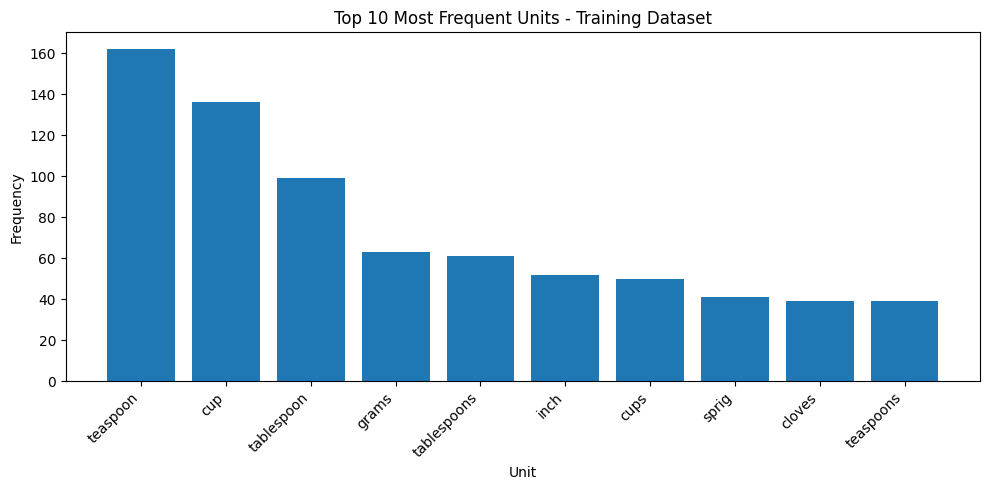

In [45]:
# plot the top frequent units in training data
plot_top_items(top_10_units, 'unit', 'Training')

## **5** Exploratory Recipe Data Analysis on Validation Dataset (Optional)<font color = red> [0 marks]</font> <br>

#### **5.1** *Execute EDA on Validation Dataset with insights (Optional)* <font color = red> [0 marks]</font> <br>
Initialise the dataset_name as ***Validation*** and call the ***plot_top_items*** for top 10 ingredients and units in the recipe data
Provide the insights for the same.



In [46]:
# initialise the dataset_name
dataset_name = 'Validation'

In [47]:
# use extract and validate tokens, categorise tokens, get top frequent items for ingredient list and unit list on validation dataframe
# Extract validation tokens and POS tags
val_tokens = flatten_list(val_df['input_tokens'].tolist())
val_pos_tags = flatten_list(val_df['pos_tokens'].tolist())

# Categorize validation tokens
val_ingredient, val_unit, val_quantity = categorize_tokens(
    val_tokens, val_pos_tags
)

Top 10 most frequent ingredients in Validation dataset:
powder: 54
Salt: 47
Oil: 39
Red: 39
seeds: 36
Chilli: 36
chopped: 31
Green: 30
Leaves: 29
Coriander: 27


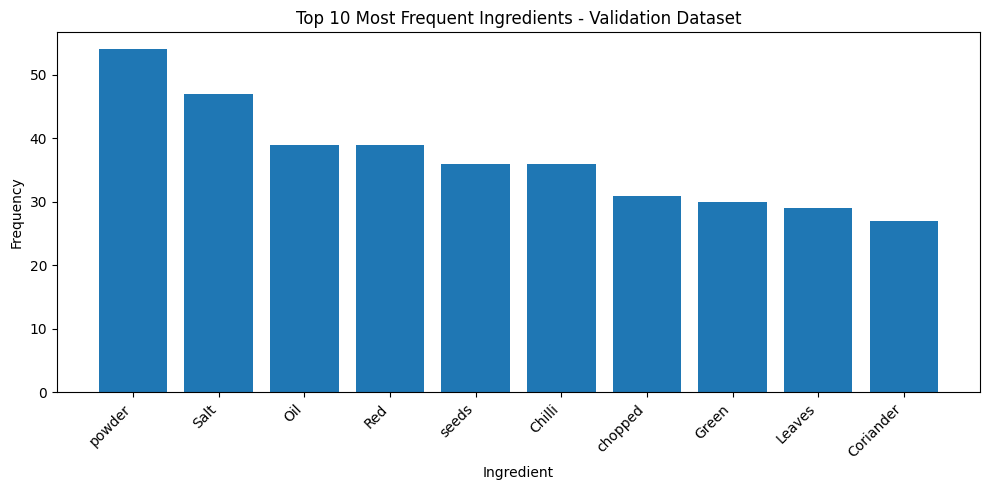

In [48]:
# plot the top frequent ingredients in validation data
top_10_val_ingredients = get_top_frequent_items(
    val_ingredient, 'ingredient', dataset_name
)

plot_top_items(
    top_10_val_ingredients, 'ingredient', dataset_name
)

Top 10 most frequent units in Validation dataset:
teaspoon: 59
cup: 57
tablespoon: 32
tablespoons: 32
cups: 24
sprig: 21
inch: 20
grams: 19
teaspoons: 18
cloves: 16


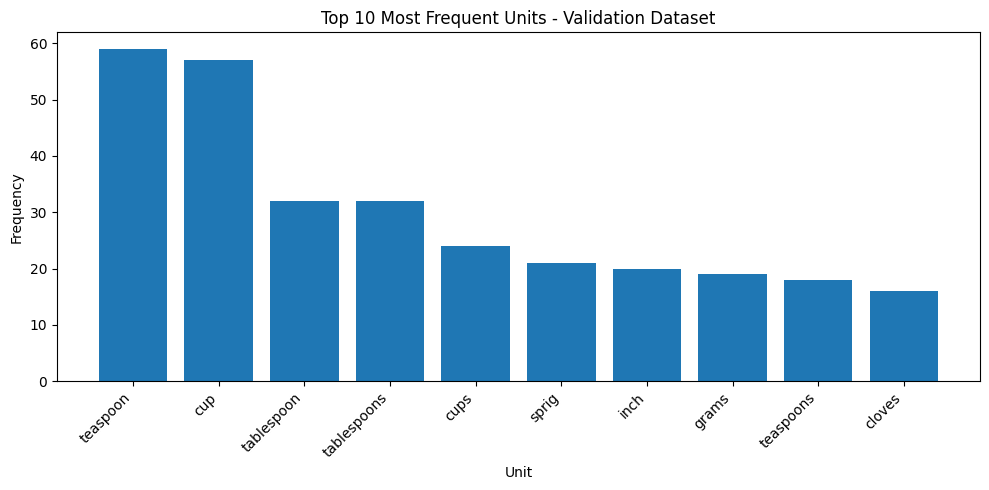

In [49]:
# plot the top frequent units in training data
top_10_val_units = get_top_frequent_items(
    val_unit, 'unit', dataset_name
)

plot_top_items(
    top_10_val_units, 'unit', dataset_name
)

## **6** Feature Extraction For CRF Model <font color = red>[30 marks]</font> <br>

### **6.1** *Define a feature functions to take each token from recipe* <font color = red>[10 marks]</font>

Define a function as ***word2features*** which takes a particular recipe and its index to work with all recipe input tokens and include custom key-value pairs.

Also, use feature key-value pairs to mark the beginning and end of the sequence and to also check whether the word belongs to unit, quantity etc. Use keyword sets for unit and quantity for differentiating feature functions well. Also make use of relevant regex patterns on fractions, whole numbers etc.

##### **6.1.1** **Define keywords for unit and quantity and create a quantity pattern to work on fractions, numbers and decimals** <font color = red>[3 marks]</font> <br>

Create sets for **unit_keywords** and ***quantity_keywords*** and include all the words relevant for measuring the ingredients such as cup, tbsp, tsp etc. and in quantity keywords, include words such as half, quarter etc.

Also suggested to use regex pattern as ***quantity_pattern*** to work with quantity in any format such as fractions, numbers and decimals.

Then, load the spacy model and process the entire sentence

In [50]:
# define unit and quantity keywords along with quantity pattern
import re

# Define unit keywords
unit_keywords = {
    'cup', 'cups',
    'tbsp', 'tablespoon', 'tablespoons',
    'tsp', 'teaspoon', 'teaspoons',
    'g', 'gram', 'grams',
    'kg', 'kilogram', 'kilograms',
    'mg', 'milligram', 'milligrams',
    'ml', 'milliliter', 'milliliters',
    'l', 'liter', 'liters', 'litre', 'litres',
    'oz', 'ounce', 'ounces',
    'lb', 'lbs', 'pound', 'pounds',
    'pinch', 'pinches',
    'clove', 'cloves',
    'piece', 'pieces',
    'slice', 'slices',
    'bunch', 'bunches',
    'sprig', 'sprigs',
    'can', 'cans',
    'packet', 'packets'
}

# Define quantity keywords
quantity_keywords = {
    'half', 'quarter', 'third',
    'one', 'two', 'three', 'four', 'five',
    'six', 'seven', 'eight', 'nine', 'ten',
    'whole', 'single', 'double',
    'few', 'several', 'dozen'
}

# Define quantity pattern for numbers, fractions, decimals and mixed fractions
quantity_pattern = re.compile(
    r'^(?:\d+\s+\d+/\d+|\d+/\d+|\d+(?:\.\d+)?)$'
)

In [51]:
# load spaCy model
nlp = spacy.load("en_core_web_sm")
print("spaCy model loaded successfully")

spaCy model loaded successfully


##### **6.1.2** **Define feature functions for CRF** <font color = red>[7 marks]</font> <br>

Define ***word2features*** function and use the parameters such as sentence and its indexing as ***sent*** and ***i*** for extracting token level features for CRF Training.
Build ***features*** dictionary, also mark the beginning and end of the sequence and use the ***unit_keywords***, ***quantity_keywords*** and ***quantity_pattern*** for knowing the presence of quantity or unit in the tokens

While building ***features*** dictionary, include
- ***Core Features*** - The core features of a token should capture its lexical
and grammatical properties. Include attributes like the raw token, its lemma, part-of-speech tag, dependency relation, and shape, as well as indicators for whether it's a stop word, digit, or punctuation. The details of the features are given below:

    - `bias` - Constant feature with a fixed value of 1.0 to aid model learning.
    - `token` - The lowercase form of the current token.
    - `lemma` - The lowercase lemma (base form) of the token.
    - `pos_tag` - Part-of-speech (POS) tag of the token.
    - `tag` - Detailed POS tag of the token.
    - `dep` - Dependency relation of the token in the sentence.
    - `shape` - Shape of the token (e.g., "Xxx" for "Milk").
    - `is_stop` - Boolean indicating if the token is a stopword.
    - `is_digit` - Boolean indicating if the token consists of only digits.
    - `has_digit` - Boolean indicating if the token contains at least one digit.
    - `has_alpha` - Boolean indicating if the token contains at least one alphabetic character.
    - `hyphenated` - Boolean indicating if the token contains a hyphen (-).
    - `slash_present` - Boolean indicating if the token contains a slash (/).
    - `is_title` - Boolean indicating if the token starts with an uppercase letter.
    - `is_upper` - Boolean indicating if the token is fully uppercase.
    - `is_punct` - Boolean indicating if the token is a punctuation mark.

- ***Improved Quantity and Unit Detection*** - Use key-value pairs to mark the presence of quantities and units in the features dictionary. Utilise the unit_keywords, quantity_keywords, and quantity_pattern to identify and flag these elements. The details of the features are given below:

    - `is_quantity` - Boolean indicating if the token matches a quantity pattern or keyword.
    - `is_unit` - Boolean indicating if the token is a known measurement unit.
    - `is_numeric` - Boolean indicating if the token matches a numeric pattern.
    - `is_fraction` - Boolean indicating if the token represents a fraction (e.g., 1/2).
    - `is_decimal` - Boolean indicating if the token represents a decimal number (e.g., 3.14).
    - `preceding_word` - The previous token in the sentence, if available.
    - `following_word` - The next token in the sentence, if available.

- ***Contextual Features*** - Incorporate contextual information by adding features for the preceding and following tokens. Include indicators like BOS and EOS to mark the beginning and end of the sequence, and utilise unit_keywords, quantity_keywords, and quantity_pattern to identify the types of neighboring tokens. The features are given below:

    - `prev_token` - The lowercase form of the previous token.
    - `prev_is_quantity` - Boolean indicating if the previous token is a quantity.
    - `prev_is_digit` - Boolean indicating if the previous token is a digit.
    - `BOS` - Boolean indicating if the token is at the beginning of the sentence.
    - `next_token` - The lowercase form of the next token.
    - `next_is_unit` - Boolean indicating if the next token is a unit.
    - `next_is_ingredient` - Boolean indicating if the next token is not a unit or quantity.
    - `EOS` - Boolean indicating if the token is at the end of the sentence.



In [52]:
# define word2features for processing each token in the sentence sent by using index i.
# use your own feature functions
def word2features(sent, i):

    # Process the entire sentence with spaCy
    doc = nlp(" ".join(sent))
    token = sent[i]
    word = doc[i]
    token_lower = token.lower()
    # --- Core Features ---

    features = {
        'bias': 1.0,
        'token': token_lower,
        'lemma': word.lemma_.lower(),
        'pos_tag': word.pos_,
        'tag': word.tag_,
        'dep': word.dep_,
        'shape': word.shape_,
        'is_stop': word.is_stop,
        'is_digit': token.isdigit(),
        'has_digit': any(char.isdigit() for char in token),
        'has_alpha': any(char.isalpha() for char in token),
        'hyphenated': '-' in token,
        'slash_present': '/' in token,
        'is_title': token.istitle(),
        'is_upper': token.isupper(),
        'is_punct': word.is_punct
    }

    # --- Improved Quantity & Unit Detection ---
    is_fraction = bool(re.fullmatch(r'\d+/\d+', token))
    is_decimal = bool(re.fullmatch(r'\d+\.\d+', token))
    is_numeric = bool(
        re.fullmatch(r'\d+(?:\.\d+)?|\d+/\d+', token)
    )

    is_quantity = (
        bool(quantity_pattern.fullmatch(token))
        or token_lower in quantity_keywords
    )

    is_unit = token_lower in unit_keywords

    features.update({
        'is_quantity': is_quantity,
        'is_unit': is_unit,
        'is_numeric': is_numeric,
        'is_fraction': is_fraction,
        'is_decimal': is_decimal,
        'preceding_word': sent[i - 1].lower() if i > 0 else '',
        'following_word': sent[i + 1].lower() if i < len(sent) - 1 else ''
    })


    # --- Contextual Features ---
    prev_token = sent[i - 1] if i > 0 else None
    next_token = sent[i + 1] if i < len(sent) - 1 else None

    features['BOS'] = (i == 0)
    features['EOS'] = (i == len(sent) - 1)

    if prev_token is not None:
        prev_lower = prev_token.lower()
        features.update({
            'prev_token': prev_lower,
            'prev_is_quantity': (
                bool(quantity_pattern.fullmatch(prev_token))
                or prev_lower in quantity_keywords
            ),
            'prev_is_digit': prev_token.isdigit()
        })

    if next_token is not None:
        next_lower = next_token.lower()
        next_is_quantity = (
            bool(quantity_pattern.fullmatch(next_token))
            or next_lower in quantity_keywords
        )

        features.update({
            'next_token': next_lower,
            'next_is_unit': next_lower in unit_keywords,
            'next_is_ingredient': (
                next_lower not in unit_keywords
                and not next_is_quantity
            )
        })

    return features

### **6.2** *Preparation of Recipe level features* <font color = red>[2 marks]</font>


##### **6.2.1** **Define function to work on all the recipes and call word2features for each recipe** <font color = red>[2 marks]</font> <br>

Define ***sent2features*** function and inputs ***sent*** as a parameter and correctly generate feature functions for each token present in the sentence

In [53]:
# define sent2features by working on each token in the sentence and correctly generate dictionaries for features
def sent2features(sent):
    return [word2features(sent, i) for i in range(len(sent))]

### **6.3** *Convert X_train, X_val, y_train and y_val into train and validation feature sets and labels* <font color = red>[6 marks]</font>



##### **6.3.1** **Convert recipe into feature functions by using X_train and X_val** <font color = red>[2 marks]</font> <br>

Create ***X_train_features*** and ***X_val_features*** as list to include the feature functions for each recipe present in training and validation sets

In [54]:
# Extract training and validation sentences and labels

X_train = train_df['input_tokens'].tolist()
X_val = val_df['input_tokens'].tolist()

y_train = train_df['pos_tokens'].tolist()
y_val = val_df['pos_tokens'].tolist()

print("Training recipes:", len(X_train))
print("Validation recipes:", len(X_val))
print("Training labels:", len(y_train))
print("Validation labels:", len(y_val))

Training recipes: 196
Validation recipes: 84
Training labels: 196
Validation labels: 84


In [55]:
# Convert input sentences into feature sets by taking training and validation dataset as X_train_features and X_val_features
X_train_features = [sent2features(sent) for sent in X_train]

X_val_features = [sent2features(sent) for sent in X_val]

In [56]:
print("Number of training recipes:", len(X_train_features))
print("Number of validation recipes:", len(X_val_features))

print("\nNumber of tokens in the first training recipe:", len(X_train_features[0]))
print("Number of feature dictionaries:", len(X_train_features[0]))

print("\nSample features for the first token:")
print(X_train_features[0][0])

Number of training recipes: 196
Number of validation recipes: 84

Number of tokens in the first training recipe: 31
Number of feature dictionaries: 31

Sample features for the first token:
{'bias': 1.0, 'token': '250', 'lemma': '250', 'pos_tag': 'NUM', 'tag': 'CD', 'dep': 'nummod', 'shape': 'ddd', 'is_stop': False, 'is_digit': True, 'has_digit': True, 'has_alpha': False, 'hyphenated': False, 'slash_present': False, 'is_title': False, 'is_upper': False, 'is_punct': False, 'is_quantity': True, 'is_unit': False, 'is_numeric': True, 'is_fraction': False, 'is_decimal': False, 'preceding_word': '', 'following_word': 'grams', 'BOS': True, 'EOS': False, 'next_token': 'grams', 'next_is_unit': True, 'next_is_ingredient': False}


##### **6.3.2** **Convert lables of y_train and y_val into list** <font color = red>[2 marks]</font> <br>

Create ***y_train_labels*** and ***y_val_labels*** by using the list of y_train and y_val

In [57]:
# Convert labels into list as y_train_labels and y_val_labels
y_train_labels = list(y_train)
y_val_labels = list(y_val)

# Verify the results
print("Number of training label sequences:", len(y_train_labels))
print("Number of validation label sequences:", len(y_val_labels))

print("\nSample training labels:", y_train_labels[0])
print("Sample validation labels:", y_val_labels[0])

Number of training label sequences: 196
Number of validation label sequences: 84

Sample training labels: ['quantity', 'unit', 'ingredient', 'ingredient', 'quantity', 'ingredient', 'ingredient', 'ingredient', 'ingredient', 'ingredient', 'unit', 'ingredient', 'quantity', 'ingredient', 'ingredient', 'quantity', 'ingredient', 'ingredient', 'quantity', 'unit', 'ingredient', 'unit', 'ingredient', 'ingredient', 'ingredient', 'ingredient', 'ingredient', 'ingredient', 'ingredient', 'ingredient', 'ingredient']
Sample validation labels: ['quantity', 'unit', 'ingredient', 'quantity', 'unit', 'ingredient', 'quantity', 'ingredient', 'unit', 'ingredient', 'quantity', 'unit', 'ingredient', 'ingredient', 'ingredient']


##### **6.3.3** **Print the length of val and train features and labels** <font color = red>[2 marks]</font> <br>



In [58]:
# print the length of train features and labels
# Print the length of training and validation features and labels

print("Length of X_train_features:", len(X_train_features))
print("Length of y_train_labels:", len(y_train_labels))

print("Length of X_val_features:", len(X_val_features))
print("Length of y_val_labels:", len(y_val_labels))

Length of X_train_features: 196
Length of y_train_labels: 196
Length of X_val_features: 84
Length of y_val_labels: 84


In [59]:
# print the length of validation features and labels
print("Length of validation features:", len(X_val_features))
print("Length of validation labels:", len(y_val_labels))

Length of validation features: 84
Length of validation labels: 84


### **6.4** *Applying weights to feature sets* <font color = red>[12 marks]</font> <br>




##### **6.4.1** **Flatten the labels of y_train** <font color = red>[2 marks]</font> <br>

Create ***y_train_flat*** to flatten the structure of nested y_train

In [60]:
# Flatten labels in y_train
y_train_flat = [label for recipe_labels in y_train for label in recipe_labels]

# Print the results
print("Length of y_train:", len(y_train))
print("Length of y_train_flat:", len(y_train_flat))

print("\nFirst 10 flattened labels:", y_train_flat[:10])


Length of y_train: 196
Length of y_train_flat: 7114

First 10 flattened labels: ['quantity', 'unit', 'ingredient', 'ingredient', 'quantity', 'ingredient', 'ingredient', 'ingredient', 'ingredient', 'ingredient']


##### **6.4.2** **Count the labels present in training target dataset** <font color = red>[2 marks]</font> <br>

Create ***label_counts*** to count the frequencies of labels present in y_train_flat and retrieve the total samples by using the values of label_counts as ***total_samples***

In [61]:
# Count label frequencies as label_counts and total_samples as getting the summation of values of label_counts
# Count label frequencies
from collections import Counter

label_counts = Counter(y_train_flat)

# Calculate total samples
total_samples = sum(label_counts.values())

# Display results
print("Label counts:", label_counts)
print("Total samples:", total_samples)

Label counts: Counter({'ingredient': 5323, 'quantity': 980, 'unit': 811})
Total samples: 7114


##### **6.4.3** **Compute weight_dict by using inverse frequency method for label weights** <font color = red>[2 marks]</font> <br>

- Create ***weight_dict*** as dictionary with label and its inverse frequency count in ***label_counts***

- Penalise ingredient label in the dictionary

In [62]:
# Compute class weights (inverse frequency method) by considering total_samples and label_counts
weight_dict = {
    label: total_samples / count
    for label, count in label_counts.items()
}

# Penalise the ingredient label
weight_dict['ingredient'] *= 2

# Display the weights
print("Class weights:")
print(weight_dict)

Class weights:
{'quantity': 7.259183673469388, 'unit': 8.771886559802713, 'ingredient': 2.672928799549126}


In [63]:
# penalise ingredient label
weight_dict['ingredient'] *= 2

# Display updated weights
print("Updated class weights:", weight_dict)

Updated class weights: {'quantity': 7.259183673469388, 'unit': 8.771886559802713, 'ingredient': 5.345857599098252}


##### **6.4.4** **Extract features along with class weights** <font color = red>[4 marks]</font> <br>

Define a function ***extract_features_with_class_weights*** to work with training and validation datasets and extract features by applying class weights





In [64]:
# Apply weights to feature extraction in extract_features_with_class_weights by using parameters such as X (input tokens), y(labels) and weight_dict (Class weights)
def extract_features_with_class_weights(X, y, weight_dict):
    X_features = []
    y_weighted = []

    for sent, labels in zip(X, y):
        sent_features = sent2features(sent)

        # Apply the class weight to each token's feature dictionary
        weighted_features = []
        for features, label in zip(sent_features, labels):
            features = features.copy()
            features['class_weight'] = weight_dict.get(label, 1.0)
            weighted_features.append(features)

        X_features.append(weighted_features)
        y_weighted.append(labels)

    return X_features, y_weighted

##### **6.4.5** **Execute extract_features_with_class_weights on training and validation datasets** <font color = red>[2 marks]</font> <br>

Create ***X_train_weighted_features*** and ***X_val_weighted_features*** for extracting training and validation features along with their weights by calling ***extract_features_with_class_weights*** on the datasets

In [65]:
# Apply manually computed class weights
# Apply manually computed class weights to training and validation datasets

X_train_weighted_features, y_train_weighted = extract_features_with_class_weights(
    X_train, y_train, weight_dict
)

X_val_weighted_features, y_val_weighted = extract_features_with_class_weights(
    X_val, y_val, weight_dict
)

# Verify the results
print("Training weighted features:", len(X_train_weighted_features))
print("Validation weighted features:", len(X_val_weighted_features))

print("\nSample weighted feature:")
print(X_train_weighted_features[0][0])

Training weighted features: 196
Validation weighted features: 84

Sample weighted feature:
{'bias': 1.0, 'token': '250', 'lemma': '250', 'pos_tag': 'NUM', 'tag': 'CD', 'dep': 'nummod', 'shape': 'ddd', 'is_stop': False, 'is_digit': True, 'has_digit': True, 'has_alpha': False, 'hyphenated': False, 'slash_present': False, 'is_title': False, 'is_upper': False, 'is_punct': False, 'is_quantity': True, 'is_unit': False, 'is_numeric': True, 'is_fraction': False, 'is_decimal': False, 'preceding_word': '', 'following_word': 'grams', 'BOS': True, 'EOS': False, 'next_token': 'grams', 'next_is_unit': True, 'next_is_ingredient': False, 'class_weight': 7.259183673469388}


## **7** Model Building and Training <font color = red>[10 marks]</font> <br>

### **7.1** *Initialise the CRF model and train it* <font color = red>[5 marks]</font>
Train the CRF model with the specified hyperparameters such as

### CRF Model Hyperparameters Explanation

| Parameter                  | Description |
|----------------------------|-------------|
| **algorithm='lbfgs'**      | Optimisation algorithm used for training. `lbfgs` (Limited-memory Broyden–Fletcher–Goldfarb–Shanno) is a quasi-Newton optimisation method. |
| **c1=0.5**                | L1 regularisation term to control sparsity in feature weights. Helps in feature selection. |
| **c2=1.0**                | L2 regularisation term to prevent overfitting by penalising large weights. |
| **max_iterations=100**     | Maximum number of iterations for model training. Higher values allow more convergence but increase computation time. |
| **all_possible_transitions=True** | Ensures that all possible state transitions are considered in training, making the model more robust. |

Use weight_dict for training CRF



In [66]:
%pip install sklearn-crfsuite


In [67]:
import sklearn_crfsuite

In [68]:
# initialise CRF model with the specified hyperparameters and use weight_dict
crf = sklearn_crfsuite.CRF(
    algorithm='lbfgs',
    c1=0.5,
    c2=1.0,
    max_iterations=100,
    all_possible_transitions=True
)

# Train the CRF model using the weighted feature sets
crf.fit(X_train_weighted_features, y_train_weighted)

print("CRF model training completed successfully.")
# train the CRF model with the weighted training data


CRF model training completed successfully.


### **7.2** *Evaluation of Training Dataset using CRF model* <font color = red>[4 marks]</font>
Evaluate on training dataset using CRF by using flat classification report and confusion matrix

Training Dataset - Classification Report
              precision    recall  f1-score   support

  ingredient     0.9991    0.9998    0.9994      5323
        unit     0.9988    1.0000    0.9994       811
    quantity     0.9990    0.9939    0.9964       980

    accuracy                         0.9990      7114
   macro avg     0.9989    0.9979    0.9984      7114
weighted avg     0.9990    0.9990    0.9990      7114



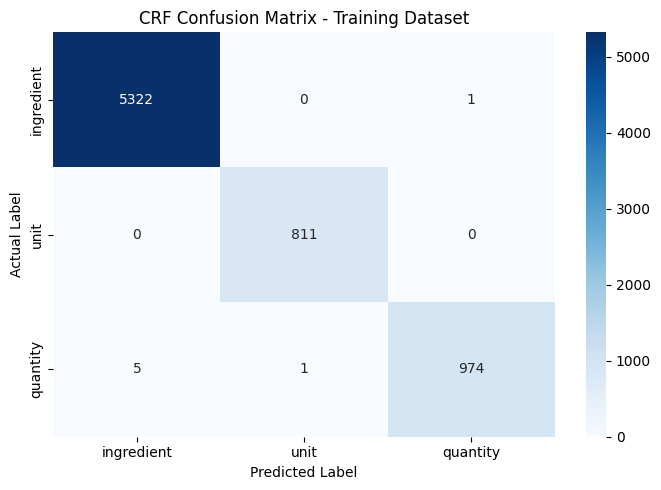

In [69]:
# evaluate on the training dataset
from sklearn_crfsuite import metrics
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Predict labels for the training dataset
y_train_pred = crf.predict(X_train_weighted_features)

# Flatten actual and predicted labels
y_train_true_flat = [label for recipe in y_train_weighted for label in recipe]
y_train_pred_flat = [label for recipe in y_train_pred for label in recipe]

# Define the labels
labels = ['ingredient', 'unit', 'quantity']

# Print flat classification report
print("Training Dataset - Classification Report")
print(metrics.flat_classification_report(
    y_train_weighted,
    y_train_pred,
    labels=labels,
    digits=4,
    zero_division=0
))

# Generate confusion matrix
cm = confusion_matrix(
    y_train_true_flat,
    y_train_pred_flat,
    labels=labels
)

# Plot confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.title("CRF Confusion Matrix - Training Dataset")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [70]:
# specify the flat classification report by using training data for evaluation

from sklearn_crfsuite import metrics

# Predict labels for the training dataset
y_train_pred = crf.predict(X_train_weighted_features)

# Generate the flat classification report
print("Flat Classification Report - Training Dataset")

print(metrics.flat_classification_report(
    y_train_weighted,
    y_train_pred,
    labels=['ingredient', 'unit', 'quantity'],
    digits=4,
    zero_division=0
))

Flat Classification Report - Training Dataset
              precision    recall  f1-score   support

  ingredient     0.9991    0.9998    0.9994      5323
        unit     0.9988    1.0000    0.9994       811
    quantity     0.9990    0.9939    0.9964       980

    accuracy                         0.9990      7114
   macro avg     0.9989    0.9979    0.9984      7114
weighted avg     0.9990    0.9990    0.9990      7114



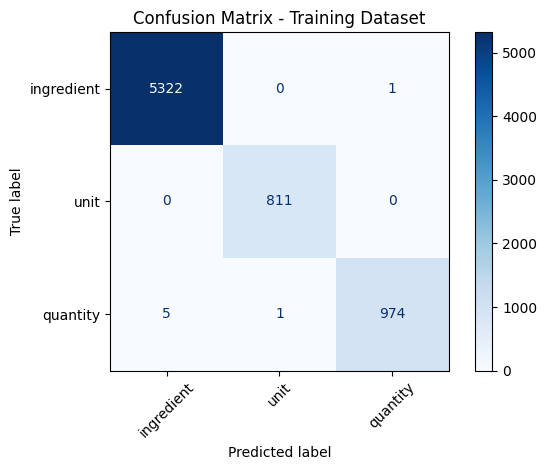

In [71]:
# create a confusion matrix on training datset
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict labels on the training dataset
y_train_pred = crf.predict(X_train_weighted_features)

# Flatten actual and predicted labels
y_train_true_flat = [label for recipe in y_train_weighted for label in recipe]
y_train_pred_flat = [label for recipe in y_train_pred for label in recipe]

# Define label order
labels = ['ingredient', 'unit', 'quantity']

# Create confusion matrix
cm = confusion_matrix(
    y_train_true_flat,
    y_train_pred_flat,
    labels=labels
)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap='Blues', values_format='d')
plt.title("Confusion Matrix - Training Dataset")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### **7.3** *Save the CRF model* <font color = red>[1 marks]</font>
Save the CRF model

In [72]:
# dump the model using joblib as crf_model.pkl
import joblib

joblib.dump(crf, 'crf_model.pkl')

print("CRF model saved successfully as crf_model.pkl")

CRF model saved successfully as crf_model.pkl


## **8** Prediction and Model Evaluation <font color = red>[3 marks]</font> <br>

### **8.1** *Predict and Evaluate the CRF model on validation set* <font color = red>[3 marks]</font>
Evaluate the metrics for CRF model by using flat classification report and confusion matrix




In [73]:
# predict the crf model on validation dataset
# Predict labels on the validation dataset
y_val_pred = crf.predict(X_val_weighted_features)

# Display predictions for the first recipe
print("Actual labels:", y_val_weighted[0])
print("Predicted labels:", y_val_pred[0])

# Verify the number of validation recipes
print("\nNumber of validation recipes:", len(X_val_weighted_features))
print("Number of predicted label sequences:", len(y_val_pred))

Actual labels: ['quantity', 'unit', 'ingredient', 'quantity', 'unit', 'ingredient', 'quantity', 'ingredient', 'unit', 'ingredient', 'quantity', 'unit', 'ingredient', 'ingredient', 'ingredient']
Predicted labels: ['quantity', 'unit', 'ingredient', 'quantity', 'unit', 'ingredient', 'quantity', 'ingredient', 'unit', 'ingredient', 'quantity', 'unit', 'ingredient', 'ingredient', 'ingredient']

Number of validation recipes: 84
Number of predicted label sequences: 84


In [74]:
# specify flat classification report

from sklearn_crfsuite import metrics

# Predict labels on the validation dataset
y_val_pred = crf.predict(X_val_weighted_features)

# Generate the flat classification report
print("Flat Classification Report - Validation Dataset")

print(metrics.flat_classification_report(
    y_val_weighted,
    y_val_pred,
    labels=['ingredient', 'unit', 'quantity'],
    digits=4,
    zero_division=0
))

Flat Classification Report - Validation Dataset
              precision    recall  f1-score   support

  ingredient     0.9991    0.9995    0.9993      2107
        unit     0.9944    0.9972    0.9958       358
    quantity     0.9951    0.9903    0.9927       411

    accuracy                         0.9979      2876
   macro avg     0.9962    0.9957    0.9959      2876
weighted avg     0.9979    0.9979    0.9979      2876



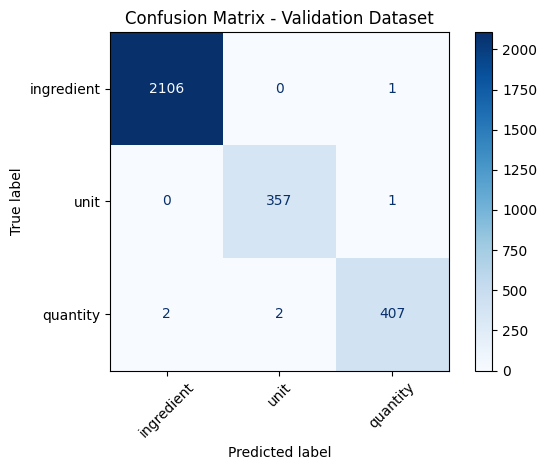

In [75]:
# create a confusion matrix on validation dataset
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict labels on the validation dataset
y_val_pred = crf.predict(X_val_weighted_features)

# Flatten actual and predicted labels
y_val_true_flat = [label for recipe in y_val_weighted for label in recipe]
y_val_pred_flat = [label for recipe in y_val_pred for label in recipe]

# Define label order
labels = ['ingredient', 'unit', 'quantity']

# Create confusion matrix
cm = confusion_matrix(
    y_val_true_flat,
    y_val_pred_flat,
    labels=labels
)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap='Blues', values_format='d')
plt.title("Confusion Matrix - Validation Dataset")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## **9** Error Analysis on Validation Data <font color = red>[10 marks]</font> <br>
Investigate misclassified samples in validation dataset and provide the insights


### **9.1** *Investigate misclassified samples in validation dataset* <font color = red>[8 marks]</font>



##### **9.1.1** Flatten the labels of validation data and initialise error data <font color = red>[2 marks]</font> <br>



Flatten the true and predicted labels and initialise the error data as ***error_data***

In [76]:
# flatten Labels and Initialise Error Data
y_val_true_flat = [label for recipe in y_val_weighted for label in recipe]
y_val_pred_flat = [label for recipe in y_val_pred for label in recipe]

# Initialise error data
error_data = []

# Verify the results
print("Total actual labels:", len(y_val_true_flat))
print("Total predicted labels:", len(y_val_pred_flat))
print("Initial error data:", error_data)

Total actual labels: 2876
Total predicted labels: 2876
Initial error data: []


##### **9.1.2** Iterate the validation data and collect Error Information<font color = red> [2 marks]</font> <br>



Iterate through validation data (X_val, y_val_labels, y_pred_val) and compare true vs. predicted labels. Collect error details, including surrounding context, previous/next tokens, and class weights, then store them in error_data

In [77]:
# iterate and collect Error Information
error_data = []

for sent, true_labels, pred_labels in zip(X_val, y_val_labels, y_val_pred):

    for i, (true_label, pred_label) in enumerate(zip(true_labels, pred_labels)):
        # Collect information only for misclassified tokens
        if true_label != pred_label:
            # get previous and next tokens with handling for boundary cases
            prev_token = sent[i - 1] if i > 0 else None
            next_token = sent[i + 1] if i < len(sent) - 1 else None

            # Get surrounding context
            context_start = max(0, i - 2)
            context_end = min(len(sent), i + 3)
            context = sent[context_start:context_end]

            # Get the class weight for the actual label
            class_weight = weight_dict.get(true_label, 1.0)

            # Store error information
            error_data.append({
                'token': sent[i],
                'true_label': true_label,
                'predicted_label': pred_label,
                'previous_token': prev_token,
                'next_token': next_token,
                'context': context,
                'class_weight': class_weight
            })

print("Total misclassified tokens:", len(error_data))
print("\nFirst 5 errors:")

for error in error_data[:5]:
    print(error)

Total misclassified tokens: 6

First 5 errors:
{'token': 'for', 'true_label': 'quantity', 'predicted_label': 'ingredient', 'previous_token': 'Oil', 'next_token': 'kneading', 'context': ['Sunflower', 'Oil', 'for', 'kneading', '4'], 'class_weight': 7.259183673469388}
{'token': 'few', 'true_label': 'quantity', 'predicted_label': 'ingredient', 'previous_token': 'Pineapple', 'next_token': 'tablespoons', 'context': ['Vark', 'Pineapple', 'few', 'tablespoons', 'Raisins'], 'class_weight': 7.259183673469388}
{'token': 'a', 'true_label': 'unit', 'predicted_label': 'quantity', 'previous_token': 'Haldi', 'next_token': 'pinch', 'context': ['powder', 'Haldi', 'a', 'pinch', 'Asafoetida'], 'class_weight': 8.771886559802713}
{'token': 'few', 'true_label': 'ingredient', 'predicted_label': 'quantity', 'previous_token': 'leaves', 'next_token': '1/4', 'context': ['Curry', 'leaves', 'few', '1/4', 'Asafoetida'], 'class_weight': 5.345857599098252}
{'token': 'pinch', 'true_label': 'quantity', 'predicted_label':

##### **9.1.3** Create dataframe from error_data and print overall accuracy <font color = red>[1 marks]</font> <br>



Change error_data into dataframe and then use it to illustrate the overall accuracy of validation data

In [78]:
# Create DataFrame and Print Overall Accuracy
import pandas as pd
from sklearn.metrics import accuracy_score

# Create DataFrame from error_data
error_df = pd.DataFrame(error_data)

# Calculate overall validation accuracy
accuracy = accuracy_score(y_val_true_flat, y_val_pred_flat)

# Display results
print("Error DataFrame:")
display(error_df.head(10))

print("\nTotal misclassified tokens:", len(error_df))
print(f"Overall Validation Accuracy: {accuracy:.4f}")
print(f"Overall Validation Accuracy: {accuracy * 100:.2f}%")

Error DataFrame:


,token,true_label,predicted_label,previous_token,next_token,context,class_weight
0,for,quantity,ingredient,Oil,kneading,"[Sunflower, Oil, for, kneading, 4]",7.259184
1,few,quantity,ingredient,Pineapple,tablespoons,"[Vark, Pineapple, few, tablespoons, Raisins]",7.259184
2,a,unit,quantity,Haldi,pinch,"[powder, Haldi, a, pinch, Asafoetida]",8.771887
3,few,ingredient,quantity,leaves,1/4,"[Curry, leaves, few, 1/4, Asafoetida]",5.345858
4,pinch,quantity,unit,Dal,Asafoetida,"[Urad, Dal, pinch, Asafoetida, hing]",7.259184
5,cloves,quantity,unit,Tomatoes,Garlic,"[Onion, Tomatoes, cloves, Garlic, Ginger]",7.259184



Total misclassified tokens: 6
Overall Validation Accuracy: 0.9979
Overall Validation Accuracy: 99.79%


##### **9.1.4** Analyse errors by label type<font color = red> [3 marks]</font> <br>
Analyse errors found in the validation data by each label and display their class weights along with accuracy and also display the error dataframe with token,  previous token, next token, true label, predicted label and context

In [79]:
# Analyse errors found in the validation data by each label


import pandas as pd

# Analyse validation errors by actual label
labels = ['ingredient', 'unit', 'quantity']
error_analysis = []

for label in labels:
    # Find validation tokens with this actual label
    indices = [
        i for i, true_label in enumerate(y_val_true_flat)
        if true_label == label
    ]

    total = len(indices)

    # Count correctly and incorrectly predicted tokens
    correct = sum(
        y_val_true_flat[i] == y_val_pred_flat[i]
        for i in indices
    )
    incorrect = total - correct

    error_analysis.append({
        'Label': label,
        'Total Samples': total,
        'Correct Predictions': correct,
        'Misclassified Samples': incorrect,
        'Error Rate (%)': round(incorrect / total * 100, 2)
                          if total > 0 else 0
    })

# Create and display the analysis table
error_analysis_df = pd.DataFrame(error_analysis)

display(error_analysis_df)

# Identify the label with the most misclassified samples
if not error_analysis_df.empty:
    most_errors = error_analysis_df.loc[
        error_analysis_df['Misclassified Samples'].idxmax()
    ]
    print(
        f"\nLabel with the most errors: {most_errors['Label']} "
        f"({most_errors['Misclassified Samples']} misclassified samples)"
    )
# and display their class weights along with accuracy

import pandas as pd

labels = ['ingredient', 'unit', 'quantity']
label_results = []

for label in labels:
    # Select tokens whose actual label matches the current label
    indices = [
        i for i, true_label in enumerate(y_val_true_flat)
        if true_label == label
    ]

    total = len(indices)

    # Count correct predictions
    correct = sum(
        y_val_true_flat[i] == y_val_pred_flat[i]
        for i in indices
    )

    errors = total - correct
    accuracy = (correct / total * 100) if total > 0 else 0.0

    label_results.append({
        'Label': label,
        'Class Weight': weight_dict.get(label, 1.0),
        'Total Samples': total,
        'Correct Predictions': correct,
        'Misclassified Samples': errors,
        'Accuracy (%)': round(accuracy, 2)
    })

# Create and display the results
label_results_df = pd.DataFrame(label_results)

display(label_results_df)
# and display the error dataframe with token, previous token, next token, true label, predicted label and context

# Select the required columns from the error DataFrame

error_columns = [
    'token',
    'previous_token',
    'next_token',
    'true_label',
    'predicted_label',
    'context'
]

error_df = pd.DataFrame(error_data)

# Display only the requested columns
error_df = error_df.reindex(columns=error_columns)

print("Validation Dataset - Misclassified Tokens")
print("Total misclassified tokens:", len(error_df))

display(error_df)

,Label,Total Samples,Correct Predictions,Misclassified Samples,Error Rate (%)
0,ingredient,2107,2106,1,0.05
1,unit,358,357,1,0.28
2,quantity,411,407,4,0.97



Label with the most errors: quantity (4 misclassified samples)


,Label,Class Weight,Total Samples,Correct Predictions,Misclassified Samples,Accuracy (%)
0,ingredient,5.345858,2107,2106,1,99.95
1,unit,8.771887,358,357,1,99.72
2,quantity,7.259184,411,407,4,99.03


Validation Dataset - Misclassified Tokens
Total misclassified tokens: 6


,token,previous_token,next_token,true_label,predicted_label,context
0,for,Oil,kneading,quantity,ingredient,"[Sunflower, Oil, for, kneading, 4]"
1,few,Pineapple,tablespoons,quantity,ingredient,"[Vark, Pineapple, few, tablespoons, Raisins]"
2,a,Haldi,pinch,unit,quantity,"[powder, Haldi, a, pinch, Asafoetida]"
3,few,leaves,1/4,ingredient,quantity,"[Curry, leaves, few, 1/4, Asafoetida]"
4,pinch,Dal,Asafoetida,quantity,unit,"[Urad, Dal, pinch, Asafoetida, hing]"
5,cloves,Tomatoes,Garlic,quantity,unit,"[Onion, Tomatoes, cloves, Garlic, Ginger]"


### **9.2** *Provide insights from the validation dataset* <font color = red>[2 marks]</font>




<font color = red>9.2 Provide Insights from the Validation Dataset</font>

The validation dataset was used to evaluate the CRF model's ability to identify recipe entities: ingredient, unit, and quantity in unseen recipes.

1. Entity identification: The classification report and confusion matrix help assess how accurately the model identifies each entity type. Precision, recall, and F1-score indicate the model's strengths and weaknesses.

2. Misclassification patterns: The error analysis identifies tokens where the predicted label differs from the actual label. These errors may arise from ambiguous ingredient names, numerical quantities, unit abbreviations, or insufficient contextual features.

3. Class-wise performance: Comparing label-wise accuracy and class weights helps identify which entity category requires further improvement. A higher class weight does not necessarily guarantee better prediction performance.

4. Recommendations: Improve the word2features() function with more relevant contextual and linguistic features, review misclassified examples, and consider adding more representative training samples. Evaluate the updated model on the validation dataset to check whether its performance improves.

Conclusion: Validation error analysis provides useful insights into the CRF model's generalisation ability and highlights opportunities to improve recipe entity recognition. Actual performance conclusions should be based on the classification report, confusion matrix, and error-analysis results generated in the notebook.

## **10** Conclusion (Optional) <font color = red>[0 marks]</font> <br>

The project “Identifying Key Entities in Recipe Data” focused on developing a Named Entity Recognition (NER) model using Conditional Random Fields (CRF) to identify and classify important information in recipe text. The main objective was to extract three entity types: ingredients, quantities, and units.

The project involved loading and preprocessing recipe data, tokenising recipe text, validating token-label alignment, and splitting the dataset into training and validation sets. Exploratory data analysis helped identify frequently occurring ingredients and measurement units. Feature engineering incorporated linguistic properties, token shapes, numerical patterns, and surrounding context to improve entity recognition. Class weights were also calculated using the inverse-frequency method to address differences in label frequencies.

The CRF model was trained using the L-BFGS optimisation algorithm with L1 and L2 regularisation. Its performance was evaluated on both training and validation datasets using flat classification reports and confusion matrices. Error analysis of validation predictions helped identify misclassified tokens and examine their surrounding context, class weights, and actual versus predicted labels.

Overall, this project demonstrates how sequence labelling and feature engineering can be applied to structured information extraction from unstructured recipe text. The developed approach provides a foundation for automating ingredient identification and quantity extraction, which can support recipe search, ingredient analysis, meal planning, and recipe database development. Further improvements could include refining contextual features, correcting inconsistent annotations, expanding the training dataset, and tuning model hyperparameters.

The final effectiveness of the model should be determined by its actual validation precision, recall, F1-score, and error patterns. These metrics are essential for understanding its reliability and identifying opportunities for further improvement.